# Dos punteros

Dos índices recorren el array y en cada paso uno de ellos avanza, descartando candidatos sin probarlos. En un array ordenado, con $i$ al principio y $j$ al final buscando $a_i + a_j = t$:

$$a_i + a_j < t \Rightarrow i \leftarrow i + 1, \qquad a_i + a_j > t \Rightarrow j \leftarrow j - 1$$

Invariante: si existe una solución $(p, q)$, entonces $i \le p < q \le j$. Si la suma se queda corta, ningún par con $a_i$ llega a $t$, porque $a_j$ ya es el mayor que queda. Cada puntero se mueve como mucho $n$ veces, así que el recorrido cuesta $O(n)$ frente a $O(n^2)$ de probar todos los pares. Otra variante usa los dos punteros en el mismo sentido (uno lee y otro escribe).

## 1. Par con suma objetivo

Dado un array ordenado y un objetivo, devolver los índices de un par que sume el objetivo o `None`. Mostrar la traza de un ejemplo y comprobar contra la fuerza bruta.

In [1]:
import random
from itertools import combinations, groupby

def par_con_suma(a, objetivo, traza=False):
    i, j = 0, len(a) - 1
    while i < j:
        suma = a[i] + a[j]
        if traza:
            print(f"i={i} j={j}  {a[i]} + {a[j]} = {suma}")
        if suma == objetivo:
            return i, j
        if suma < objetivo:
            i += 1
        else:
            j -= 1
    return None

print(par_con_suma([1, 3, 4, 6, 8, 11], 10, traza=True))

random.seed(1)
for _ in range(1000):
    a = sorted(random.choices(range(-20, 20), k=random.randint(0, 15)))
    t = random.randint(-30, 30)
    resultado = par_con_suma(a, t)
    assert (resultado is not None) == any(x + y == t for x, y in combinations(a, 2))
    if resultado:
        i, j = resultado
        assert i < j and a[i] + a[j] == t

i=0 j=5  1 + 11 = 12
i=0 j=4  1 + 8 = 9
i=1 j=4  3 + 8 = 11
i=1 j=3  3 + 6 = 9
i=2 j=3  4 + 6 = 10
(2, 3)


## 2. Eliminar duplicados in situ

Dado un array ordenado, dejar al principio cada valor como mucho `maximo` veces y devolver cuántos elementos quedan, sin listas auxiliares: un puntero lector recorre el array y uno escritor marca dónde va el siguiente elemento que se conserva. Un elemento se conserva si no coincide con el que está `maximo` posiciones por detrás en la parte ya escrita.

In [2]:
def elimina_duplicados(a, maximo=1):
    escritor = 0
    for lector in range(len(a)):
        if escritor < maximo or a[lector] != a[escritor - maximo]:
            a[escritor] = a[lector]
            escritor += 1
    return escritor

def elimina_duplicados_bruto(a, maximo=1):
    return [x for _, grupo in groupby(a) for x in list(grupo)[:maximo]]

a = [1, 1, 1, 2, 2, 3, 4, 4, 4, 4]
for maximo in (1, 2):
    copia = a[:]
    k = elimina_duplicados(copia, maximo)
    print(f"máximo {maximo}: {copia[:k]}")

for _ in range(1000):
    a = sorted(random.choices(range(6), k=random.randint(0, 15)))
    maximo = random.randint(1, 3)
    copia = a[:]
    k = elimina_duplicados(copia, maximo)
    assert copia[:k] == elimina_duplicados_bruto(a, maximo)

máximo 1: [1, 2, 3, 4]
máximo 2: [1, 1, 2, 2, 3, 4, 4]


## 3. 3-sum

Encontrar todas las ternas distintas de valores que suman 0. Ordenar y, para cada primer elemento, buscar el par restante con dos punteros: $O(n^2)$ frente a $O(n^3)$. Saltar los valores repetidos para no duplicar ternas y comprobar contra la fuerza bruta con `combinations`.

In [3]:
def tres_suma(a, objetivo=0):
    a, ternas = sorted(a), []
    for k in range(len(a) - 2):
        if k and a[k] == a[k - 1]:
            continue
        i, j = k + 1, len(a) - 1
        while i < j:
            suma = a[k] + a[i] + a[j]
            if suma < objetivo:
                i += 1
            elif suma > objetivo:
                j -= 1
            else:
                ternas.append((a[k], a[i], a[j]))
                i += 1
                while i < j and a[i] == a[i - 1]:
                    i += 1
                j -= 1
    return ternas

def tres_suma_bruta(a, objetivo=0):
    return sorted({t for t in combinations(sorted(a), 3) if sum(t) == objetivo})

for _ in range(500):
    a = random.choices(range(-8, 9), k=random.randint(0, 14))
    assert tres_suma(a) == tres_suma_bruta(a)
print(tres_suma([-1, 0, 1, 2, -1, -4]))

[(-1, -1, 2), (-1, 0, 1)]


## 4. Contenedor con más agua

Dadas las alturas de unas líneas verticales, elegir dos que, junto con el eje, formen el recipiente de mayor área $\min(h_i, h_j) \cdot (j - i)$. Empezar por los extremos y mover siempre el más bajo: con él como límite, cualquier otro par es más estrecho y no más alto. Comprobar contra la fuerza bruta y dibujar la solución.

49 (1, 8)


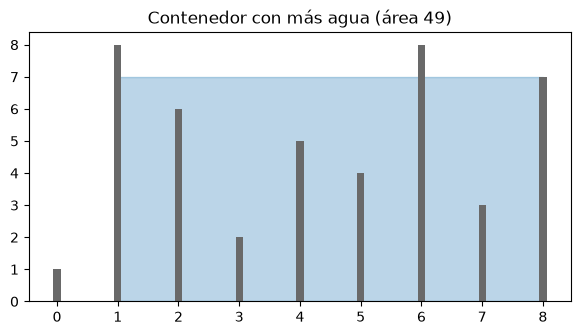

In [4]:
import matplotlib.pyplot as plt

def mas_agua(alturas):
    i, j, mejor = 0, len(alturas) - 1, (0, 0, 0)
    while i < j:
        area = min(alturas[i], alturas[j]) * (j - i)
        if area > mejor[0]:
            mejor = (area, i, j)
        if alturas[i] < alturas[j]:
            i += 1
        else:
            j -= 1
    return mejor

for _ in range(500):
    h = random.choices(range(10), k=random.randint(2, 15))
    assert mas_agua(h)[0] == max(min(h[i], h[j]) * (j - i) for i, j in combinations(range(len(h)), 2))

alturas = [1, 8, 6, 2, 5, 4, 8, 3, 7]
area, i, j = mas_agua(alturas)
print(area, (i, j))

fig, eje = plt.subplots(figsize=(7, 3.5))
eje.fill_between([i, j], min(alturas[i], alturas[j]), color="tab:blue", alpha=0.3)
eje.bar(range(len(alturas)), alturas, width=0.12, color="dimgray")
eje.set_xticks(range(len(alturas)))
eje.set_title(f"Contenedor con más agua (área {area})")
plt.show()

## 5. Palíndromo ignorando signos

Decidir si una frase es palíndroma ignorando espacios, signos de puntuación, mayúsculas y tildes (la `ñ` se mantiene). Usar dos punteros que se saltan lo que no es letra o dígito, sin construir la cadena limpia, y comprobarlo contra la versión que limpia la cadena y la invierte.

In [5]:
SIN_TILDES = str.maketrans("áéíóúü", "aeiouu")

def base(c):
    return c.lower().translate(SIN_TILDES)

def es_palindromo(frase):
    i, j = 0, len(frase) - 1
    while i < j:
        if not frase[i].isalnum():
            i += 1
        elif not frase[j].isalnum():
            j -= 1
        elif base(frase[i]) != base(frase[j]):
            return False
        else:
            i, j = i + 1, j - 1
    return True

def es_palindromo_bruto(frase):
    limpia = [base(c) for c in frase if c.isalnum()]
    return limpia == limpia[::-1]

frases = ["¿Acaso hubo búhos acá?", "Dábale arroz a la zorra el abad", "A man, a plan, a canal: Panama",
          "Esto no es un palíndromo", "0P"]
for frase in frases:
    assert es_palindromo(frase) == es_palindromo_bruto(frase)
    print(f"{frase:32} {es_palindromo(frase)}")

for _ in range(2000):
    frase = "".join(random.choices("aAáñÑ ,.!b", k=random.randint(0, 10)))
    assert es_palindromo(frase) == es_palindromo_bruto(frase)

¿Acaso hubo búhos acá?           True
Dábale arroz a la zorra el abad  True
A man, a plan, a canal: Panama   True
Esto no es un palíndromo         False
0P                               False
